# Локальные эксперименты на CPU

ZIP конкурса нужен в `data/petfinder-adoption-prediction.zip` (после клонирования: `git lfs pull`).

По умолчанию распаковываются только CSV и запускаются Dummy + Logistic Regression.

Для всех пяти моделей выберите `configs/experiments.yaml`.

Фото и JSON для них не нужны: их распаковка включается отдельно для полного EDA.

In [1]:
import sys
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo

candidates = [Path.cwd() / 'adoption_prediction', Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p.resolve() for p in candidates if (p / 'src/train.py').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Откройте notebook внутри репозитория adoption_prediction')
sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
import yaml
from IPython.display import display, Image
from src.prepare_data import default_data_source, resolve_data_root
from src.data import load_data
from src.eda import run_eda
from src.train import environment, run_cv, fit_submission
from src.report import build_report
from src.evaluate import group_bootstrap, save_json

print('Project:', PROJECT_ROOT)
display(environment())

Project: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction


{'python': '3.9.6',
 'packages': {'numpy': '1.26.4',
  'pandas': '2.2.3',
  'scikit-learn': '1.5.2',
  'scipy': '1.13.1',
  'catboost': '1.2.8',
  'matplotlib': '3.9.4',
  'PyYAML': '6.0.2',
  'joblib': '1.4.2'}}

In [10]:
DATA_SOURCE = default_data_source()  # Можно заменить на путь к ZIP или папке CSV.
INCLUDE_MEDIA = False  # True — распаковать также все JPG и JSON.
# CONFIG_PATH = PROJECT_ROOT / 'configs/baseline.yaml'
CONFIG_PATH = PROJECT_ROOT / 'configs/experiments.yaml'
RUN_REFIT = True
RUN_DIR = PROJECT_ROOT / 'outputs' / datetime.now(ZoneInfo('Europe/Moscow')).strftime('local_%Y%m%d_%H%M%S')

CONFIG = yaml.safe_load(CONFIG_PATH.read_text())
DATA_ROOT = resolve_data_root(DATA_SOURCE, include_media=INCLUDE_MEDIA)
train, test = load_data(DATA_ROOT)
print('Data:', DATA_ROOT)
print('Output:', RUN_DIR)
print('Train:', train.shape, 'test:', test.shape)
display(CONFIG)

Data: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/data/raw/petfinder-adoption-prediction/2083562071-1794647197613683780
Output: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/local_20261114_161602
Train: (14993, 24) test: (3972, 23)


{'seed': 42,
 'split': 'stratified_group',
 'n_splits': 5,
 'models': ['dummy',
  'logreg_tabular',
  'logreg_text',
  'catboost_regressor',
  'catboost_classifier'],
 'bootstrap_repeats': 500,
 'logreg': {'C': 1.0, 'max_iter': 1500},
 'text': {'max_features': 20000},
 'catboost': {'iterations': 400,
  'depth': 6,
  'learning_rate': 0.05,
  'l2_leaf_reg': 3,
  'thread_count': 2}}

## EDA

При `INCLUDE_MEDIA=False` наличие самих изображений и JSON не проверяется, если они еще не распакованы.

{'train': {'shape': [14993, 24],
  'missing_columns': [],
  'null_counts': {'Type': 0,
   'Name': 1265,
   'Age': 0,
   'Breed1': 0,
   'Breed2': 0,
   'Gender': 0,
   'Color1': 0,
   'Color2': 0,
   'Color3': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0,
   'Health': 0,
   'Quantity': 0,
   'Fee': 0,
   'State': 0,
   'RescuerID': 0,
   'VideoAmt': 0,
   'Description': 13,
   'PetID': 0,
   'PhotoAmt': 0,
   'AdoptionSpeed': 0},
  'empty_string_counts': {'Name': 1265, 'Description': 13},
  'duplicate_rows': 0,
  'duplicate_pet_ids': 0,
  'repeated_nonempty_descriptions': 973,
  'nonempty_descriptions_with_non_ascii': 597,
  'invalid_code_counts': {'Type': 0,
   'Gender': 0,
   'MaturitySize': 0,
   'FurLength': 0,
   'Health': 0,
   'Vaccinated': 0,
   'Dewormed': 0,
   'Sterilized': 0},
  'negative_numeric_counts': {'Age': 0,
   'Quantity': 0,
   'Fee': 0,
   'VideoAmt': 0,
   'PhotoAmt': 0},
  'non_numeric_counts': {'Age': 0,
 

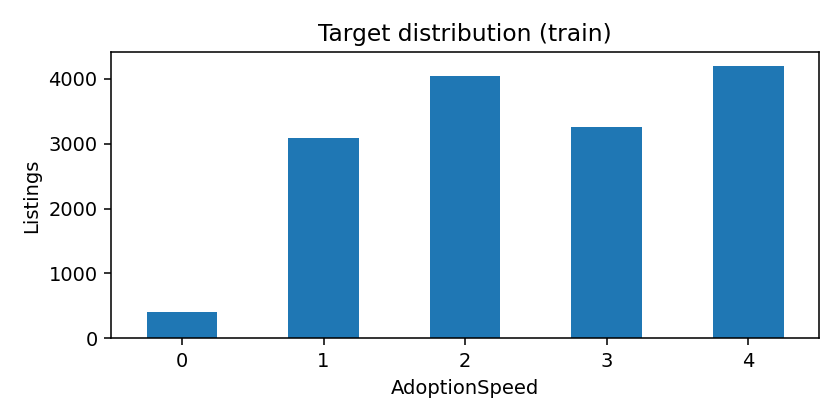

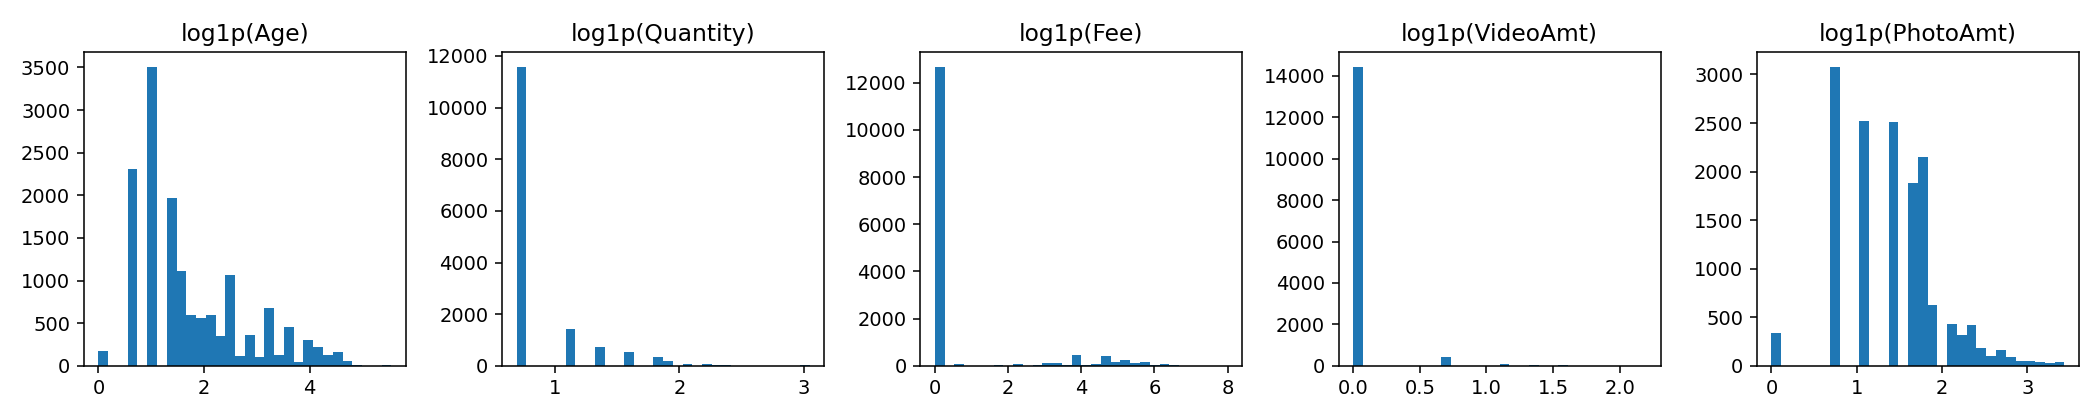

In [6]:
audit = run_eda(train, test, RUN_DIR / 'eda', DATA_ROOT)
display(audit)
display(Image(filename=str(RUN_DIR / 'eda/class_distribution.png')))
display(Image(filename=str(RUN_DIR / 'eda/numeric_distributions.png')))

dummy fold=0 QWK=0.0
dummy fold=1 QWK=0.0
dummy fold=2 QWK=0.0
dummy fold=3 QWK=0.0
dummy fold=4 QWK=0.0
logreg_tabular fold=0 QWK=0.2776697008373491
logreg_tabular fold=1 QWK=0.2694510757059084
logreg_tabular fold=2 QWK=0.25271877343914795
logreg_tabular fold=3 QWK=0.2683764231492842
logreg_tabular fold=4 QWK=0.22530276047171127
logreg_text fold=0 QWK=0.2676767428778206
logreg_text fold=1 QWK=0.2633319334838554
logreg_text fold=2 QWK=0.27813287989825763
logreg_text fold=3 QWK=0.27989981201851166
logreg_text fold=4 QWK=0.23805613152823824
catboost_regressor fold=0 QWK=0.25790017014622557
catboost_regressor fold=1 QWK=0.2592513544662671
catboost_regressor fold=2 QWK=0.26725143808079865
catboost_regressor fold=3 QWK=0.26000350014246854
catboost_regressor fold=4 QWK=0.2352800311312
catboost_classifier fold=0 QWK=0.34094313624764727
catboost_classifier fold=1 QWK=0.33357971686517207
catboost_classifier fold=2 QWK=0.3432728360943791
catboost_classifier fold=3 QWK=0.3380204784425833
catboost

,model,qwk_mean,qwk_std,oof_qwk,oof_macro_f1,oof_accuracy,oof_mae,oof_recall_class_0,oof_severe_error_rate,seconds
4,catboost_classifier,0.329912,0.020539,0.329782,0.286963,0.389782,0.967185,0.000000,0.268459,366.950884
2,logreg_text,0.265419,0.016804,0.265129,0.275949,0.360168,1.037351,0.002439,0.296605,80.719440
1,logreg_tabular,0.258704,0.020738,0.258383,0.268050,0.355566,1.042553,0.004878,0.301274,6.712379
3,catboost_regressor,0.255937,0.012105,0.256175,0.166034,0.283132,0.888215,0.000000,0.161809,36.384537
0,dummy,0.000000,0.000000,-0.007848,0.118782,0.266191,1.424331,0.000000,0.477890,0.076425


Report: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/local_20261114_160014/experiments/report.md


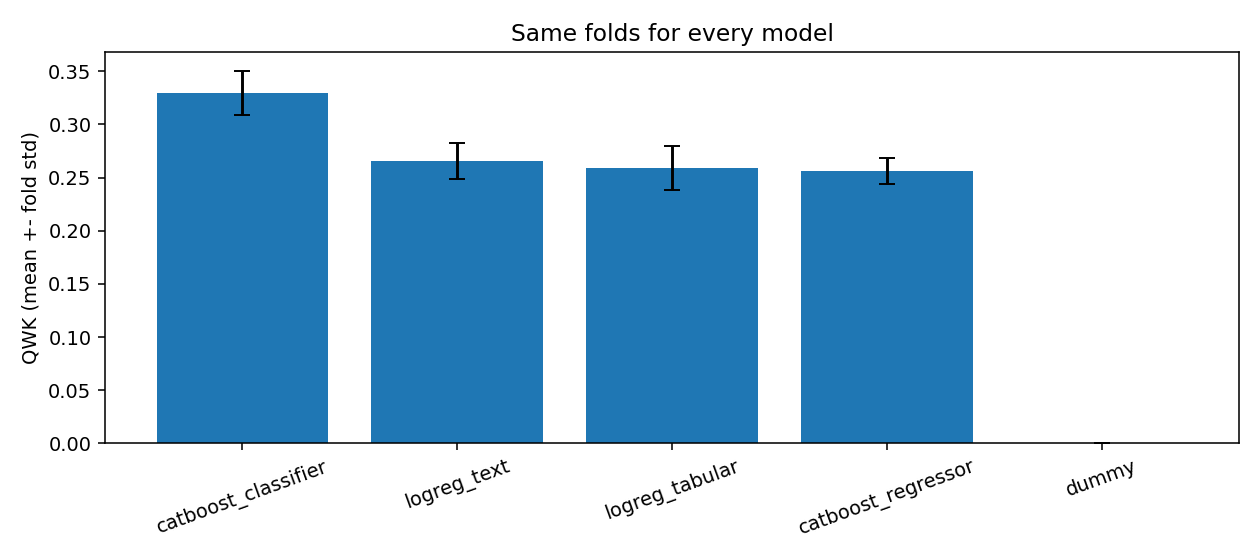

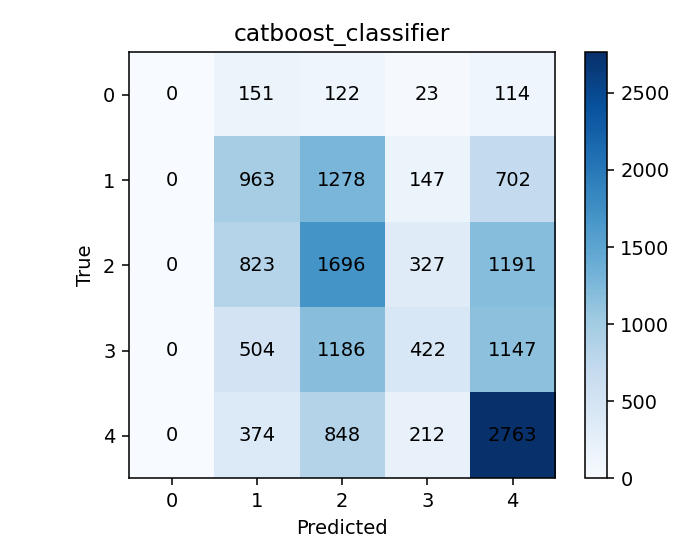

,PetID,RescuerID,Type,Age,Quantity,PhotoAmt,fold,y_true,prediction,absolute_error
0,b26fcffaf,8e554ad58cf9b09b732e8fcbbe6dbf34,2,18,1,2.0,0,0,4,4
1,23a5c1e87,ba3fa267d61cbaf919aed9d237f9180b,2,12,1,5.0,2,0,4,4
2,0c0214da4,7a1a2074370b61db1756de90bece73bf,2,24,5,1.0,3,0,4,4


In [7]:
summary = run_cv(train, CONFIG, RUN_DIR / 'experiments')
display(summary)
report_path = build_report(RUN_DIR / 'experiments')
print('Report:', report_path)
display(Image(filename=str(RUN_DIR / 'experiments/model_comparison.png')))
best_model = summary.iloc[0]['model']
display(Image(filename=str(RUN_DIR / 'experiments' / best_model / 'confusion_matrix.png')))
display(pd.read_csv(RUN_DIR / 'experiments' / best_model / 'errors.csv').head(3))

## Гипотеза о тексте

Этот блок выполняется, если в конфиге есть обе Logistic Regression (tabular и text).

Интервал пересэмплирует авторов и относится к уже полученным OOF, без переобучения моделей.

In [8]:
if {'logreg_tabular', 'logreg_text'}.issubset(set(summary.model)):
    results = RUN_DIR / 'experiments'
    text_oof = pd.read_csv(results / 'logreg_text/oof.csv')
    tab_oof = pd.read_csv(results / 'logreg_tabular/oof.csv')
    paired = text_oof.merge(tab_oof[['PetID', 'fold', 'y_true', 'prediction']],
                            on=['PetID', 'fold', 'y_true'], suffixes=('', '_tab'), validate='one_to_one')
    assert len(paired) == len(train)
    by_model = summary.set_index('model')
    result = {
        'delta_oof_qwk_text_minus_tabular': float(by_model.loc['logreg_text', 'oof_qwk'] - by_model.loc['logreg_tabular', 'oof_qwk']),
        'paired_group_bootstrap': group_bootstrap(paired, repeats=CONFIG.get('bootstrap_repeats', 500),
                                                  seed=CONFIG['seed'], other='prediction_tab'),
    }
    save_json(result, results / 'text_hypothesis.json')
    display(result)

{'delta_oof_qwk_text_minus_tabular': 0.006746106445250866,
 'paired_group_bootstrap': {'low': -0.01000815126665781,
  'high': 0.025044209024079847,
  'valid_repeats': 500,
  'requested_repeats': 500}}

## Refit и submission (по желанию)

Если RUN_REFIT=True, победитель локальной CV обучается на всем train и предсказывает test.

In [11]:
if RUN_REFIT:
    sample_candidates = [DATA_ROOT / 'sample_submission.csv', DATA_ROOT / 'test/sample_submission.csv']
    sample_path = next((p for p in sample_candidates if p.is_file()), None)
    submission = fit_submission(train, test, CONFIG, best_model, RUN_DIR / 'refit', sample_path)
    display(submission.head())
    print('Submission:', RUN_DIR / 'refit/submission.csv')

,PetID,AdoptionSpeed
0,e2dfc2935,4
1,f153b465f,1
2,3c90f3f54,1
3,e02abc8a3,4
4,09f0df7d1,4


Submission: /Users/mac/Documents/RND_ML_course_ITMO/adoption_prediction/outputs/local_20261114_161602/refit/submission.csv
